# KNN (K-Nearest-Neighbors)

We will be performing classification on the Iris dataset using KNN.<br>
The Iris data is perhaps the best known database to be found in the pattern recognition literature. The dataset contains 3 classes of 50 instances each, where each class refers to a type of iris plant.



Features:
<ol>
<li>sepal length in cm </li>
<li>sepal width in cm </li>
<li>petal length in cm </li>
<li>petal width in cm </li>
</ol>

Class:
<ul>
<li>Iris Setosa </li>
<li>Iris Versicolour </li>
<li>Iris Virginica </li>
    </ul>

In [1]:
import warnings
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores*"
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn import neighbors, datasets
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


# pip install -U scikit-learn --user if you have an import error due to DecisionBoundaryDisplay 



# import some data to play with
iris = datasets.load_iris()

# np.c_ is the numpy concatenate function
iris_df = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                      columns= iris['feature_names'] + ['target'])
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


In [2]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:

X = iris.data[:, :4]
y = iris.target

In [4]:
# split the data into train and test sets
x_train, x_test, y_train, y_test= train_test_split(X, y,
                                                   test_size= 0.2,
                                                   shuffle= True, #shuffle the data to avoid bias
                                                   random_state= 0)
print(f'training set size: {x_train.shape[0]} samples \ntest set size: {x_test.shape[0]} samples')

training set size: 120 samples 
test set size: 30 samples


We define kNN classifier with class KNeighborsClassifier , hyperparameter n_neighbors value is 100.

In [5]:
# create a knn, k = 100
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=100)

For training the model only train set is used.

In [6]:
# fit to the train set
knn.fit(x_train, y_train);

Classifier is trained now, information about the train data has been extracted and save inside the object knn . Method fit() is present in all the estimators of the package scikit-learn . Documentation defines estimator as "An object that fits a model based on some training data and is capable of inferring some properties on new data. It can be, for instance, a classifier or a regressor. All estimators implement the fit() method".

### Make predictions

Fitted model is now able to receive the input data and produce predictions of the labels. We will predict labels for both train and test data.

In [7]:
ytrain_pred = knn.predict(x_train) # predict on train set
ytest_pred = knn.predict(x_test) # predict on test set

### Evaluation

Comparison of predicted and true label can tell us valuable information about how well our model performs. We will use the accuracy measure.

In [8]:
# accuracy
acc_train = accuracy_score(y_train,ytrain_pred)
acc_test =accuracy_score(y_test, ytest_pred)
print(f"Train set: {acc_train}")
print(f"Test set: {acc_test}")

Train set: 0.7666666666666667
Test set: 0.5666666666666667


The accuracy of the classifier on the train set should be the same or a bit better than on the test set. If the test accuracy is much worse, we are overfitting the model and have to change parameters. In kNN, the value of n_neighbors is the key to achieve the best results.

# Activities 
- Our choice of 100 for K was arbitrary - what effect do different K values have on the results? 
- The default distance used is the Minkowski when p=2 which means the standard Euclidean distance. Try changing the metric (cosine, manhattan distances ...) and see the results. ( PS: You can define a general function to change the distance accordingly ) <br>
<i><b>def mydist(X1, X2): <br>
    return spatial.distance.euclidean(X1, X2)</i></b> <br>
- Normalize the data and rewrite the program to check whether the results would be better. 

## Solution des activités

### Activité 1 — Effet de la valeur de K

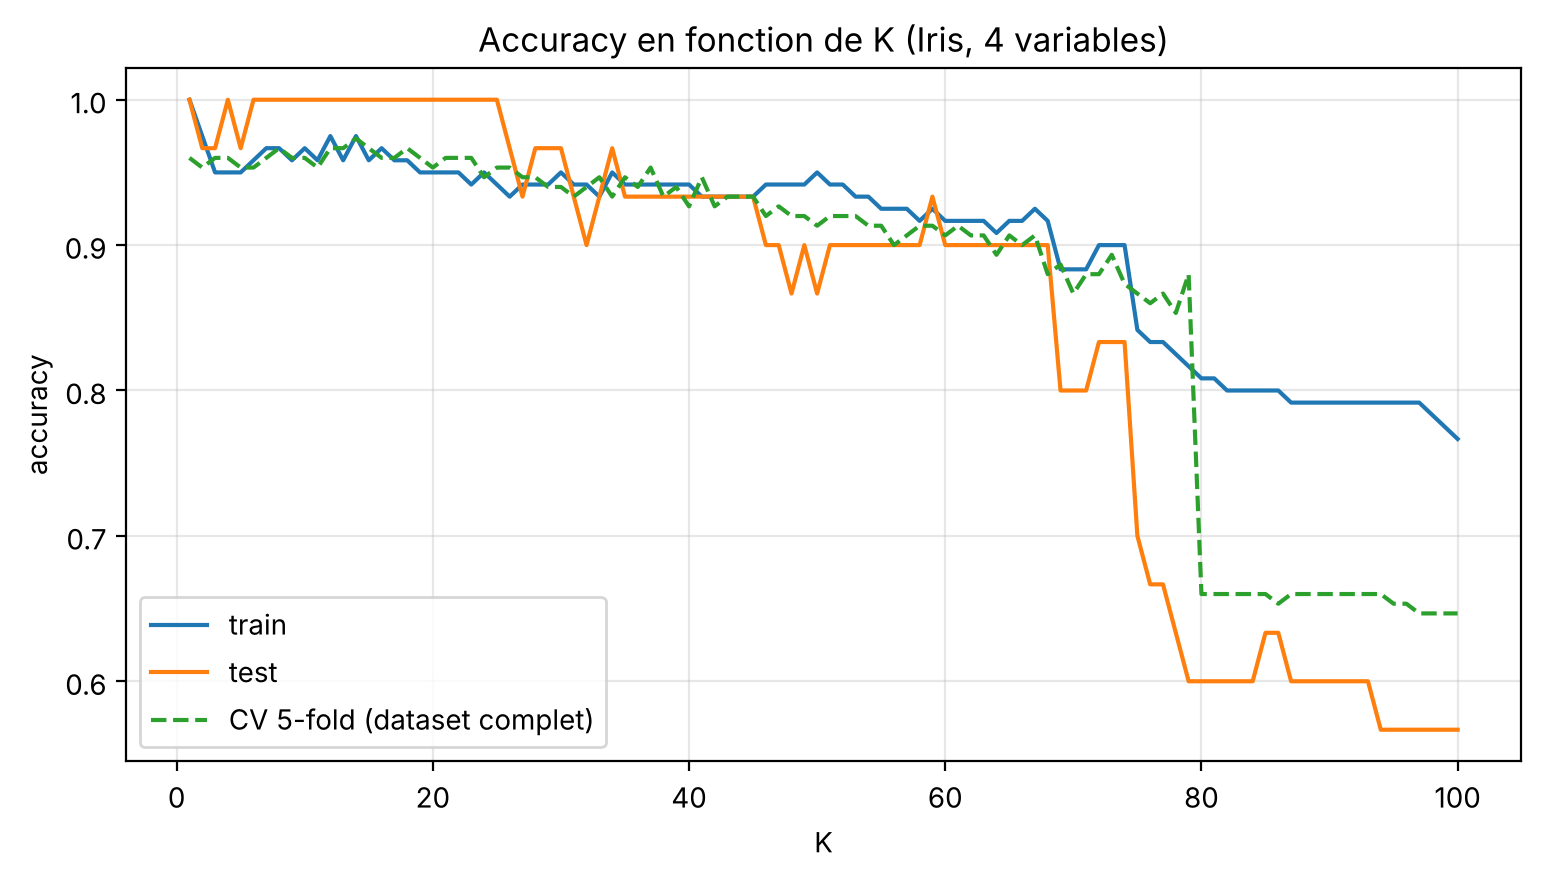

  K  train  test    CV
  1  1.000 1.000 0.960
  3  0.950 0.967 0.960
  5  0.950 0.967 0.953
  7  0.967 1.000 0.960
 10  0.967 1.000 0.960
 15  0.958 1.000 0.967
 20  0.950 1.000 0.953
 30  0.950 0.967 0.940
 50  0.950 0.867 0.913
 75  0.842 0.700 0.867
100  0.767 0.567 0.647

Meilleur K selon la CV : K=14 (CV=0.973)


In [9]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
ks = range(1, 101)
tr, te, cv = [], [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(x_train, y_train)
    tr.append(accuracy_score(y_train, m.predict(x_train)))
    te.append(accuracy_score(y_test, m.predict(x_test)))
    cv.append(cross_val_score(KNeighborsClassifier(n_neighbors=k), X, y, cv=skf).mean())

plt.figure(figsize=(9, 4.5))
plt.plot(ks, tr, label="train")
plt.plot(ks, te, label="test")
plt.plot(ks, cv, label="CV 5-fold (dataset complet)", linestyle="--")
plt.xlabel("K"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("Accuracy en fonction de K (Iris, 4 variables)")
plt.show()

res = pd.DataFrame({"K": list(ks), "train": tr, "test": te, "CV": cv})
print(res.loc[res.K.isin([1, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100])].round(3).to_string(index=False))
best = res.loc[res.CV.idxmax()]
print(f"\nMeilleur K selon la CV : K={int(best.K)} (CV={best.CV:.3f})")

**Observations**
- **K très petit (K=1)** : train = 1.0 (le point est son propre voisin) → modèle très flexible, frontière irrégulière, risque de sur-apprentissage / sensibilité au bruit.
- **K intermédiaire (≈ 5 à 20)** : meilleur compromis ; test ≈ 0.97–1.0 et CV ≈ 0.95–0.97. Le meilleur K selon la validation croisée est **K = 14 (CV = 0.973)**, ce qui est cohérent avec la règle du cours (K optimal généralement entre 3 et 10, ici un peu plus grand).
- **K très grand (K=100)** : train = 0.77 et test = 0.57 → **sous-apprentissage** : avec 120 points d'apprentissage, K=100 revient à voter presque sur tout le jeu de données, donc à prédire presque toujours la classe majoritaire (ici les trois classes sont quasi équilibrées, d'où une accuracy proche du hasard).
- Le choix arbitraire K=100 du notebook était donc **mauvais** : l'accuracy test (0.57) est même *inférieure* à celle du train (0.77), signe d'un modèle trop lissé. K doit être choisi par validation croisée, pas arbitrairement.

### Activité 2 — Changer la métrique de distance

In [10]:
from scipy import spatial

def mydist(X1, X2):
    return spatial.distance.euclidean(X1, X2)

def manh(X1, X2):
    return spatial.distance.cityblock(X1, X2)

def cosine(X1, X2):
    return spatial.distance.cosine(X1, X2)

def cheb(X1, X2):
    return spatial.distance.chebyshev(X1, X2)

X = iris.data[:, :4]; y = iris.target   # (X avait été réduit à 2 variables plus haut dans le TP original)
metrics = {
    "euclidean (mydist)": mydist,
    "manhattan": manh,
    "cosine": cosine,
    "chebyshev": cheb,
    "minkowski p=3": lambda a, b: spatial.distance.minkowski(a, b, p=3),
}
rows = []
for k in [5, 100]:
    for name, f in metrics.items():
        m = KNeighborsClassifier(n_neighbors=k, metric=f, algorithm="brute").fit(x_train, y_train)
        rows.append({"K": k, "métrique": name,
                     "train": accuracy_score(y_train, m.predict(x_train)),
                     "test": accuracy_score(y_test, m.predict(x_test)),
                     "CV 5-fold": cross_val_score(KNeighborsClassifier(n_neighbors=k, metric=f, algorithm="brute"), X, y, cv=skf).mean()})
pd.DataFrame(rows).round(3)

,K,métrique,train,test,CV 5-fold
0,5,euclidean (mydist),0.950,0.967,0.953
1,5,manhattan,0.950,1.000,0.953
2,5,cosine,0.967,1.000,0.953
3,5,chebyshev,0.958,1.000,0.973
4,5,minkowski p=3,0.950,0.967,0.953
5,100,euclidean (mydist),0.767,0.567,0.647
6,100,manhattan,0.817,0.633,0.640
7,100,cosine,0.692,0.567,0.667
8,100,chebyshev,0.725,0.567,0.653
9,100,minkowski p=3,0.750,0.567,0.647


**Observations**
- Pour **K=5**, toutes les métriques donnent des résultats très proches (test 0.97–1.0, CV ≈ 0.95–0.97) : sur Iris, les classes sont bien séparées, la métrique a peu d'influence. Chebyshev est légèrement meilleure en CV (0.973), Manhattan/Cosine/Chebyshev atteignent 1.0 sur ce jeu de test (30 échantillons : une erreur = 3,3 points, donc ces différences ne sont **pas significatives**).
- Pour **K=100**, la mauvaise performance est due à K, pas à la métrique : aucune distance ne corrige un K trop grand.
- Conclusion : le choix de la distance est un hyperparamètre secondaire sur Iris ; il compte davantage quand les variables ont des échelles/natures différentes (Hamming pour le catégoriel, cosinus pour des données de type texte/directions).

### Activité 3 — Normalisation des données

In [11]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline

rows = []
for k in [5, 100]:
    for name, scaler in [("sans normalisation", None), ("MinMaxScaler [0,1]", MinMaxScaler()), ("StandardScaler (z-score)", StandardScaler())]:
        mk = lambda: KNeighborsClassifier(n_neighbors=k) if scaler is None else make_pipeline(type(scaler)(), KNeighborsClassifier(n_neighbors=k))
        m = mk().fit(x_train, y_train)   # le scaler est ajusté sur le train uniquement (pas de fuite de données)
        rows.append({"K": k, "prétraitement": name,
                     "train": accuracy_score(y_train, m.predict(x_train)),
                     "test": accuracy_score(y_test, m.predict(x_test)),
                     "CV 5-fold": cross_val_score(mk(), X, y, cv=skf).mean()})
pd.DataFrame(rows).round(3)

,K,prétraitement,train,test,CV 5-fold
0,5,sans normalisation,0.950,0.967,0.953
1,5,"MinMaxScaler [0,1]",0.950,1.000,0.960
2,5,StandardScaler (z-score),0.958,1.000,0.953
3,100,sans normalisation,0.767,0.567,0.647
4,100,"MinMaxScaler [0,1]",0.850,0.667,0.667
5,100,StandardScaler (z-score),0.833,0.633,0.653


**Observations**
- Pour **K=5**, la normalisation (Min-Max ou z-score) donne des résultats équivalents ou très légèrement meilleurs (test 1.0, CV 0.953–0.960 contre 0.953 sans normalisation) : l'amélioration est faible car les 4 variables d'Iris sont déjà dans des échelles comparables (cm).
- Pour **K=100**, la normalisation améliore le train (0.77 → 0.83–0.85) et le test (0.57 → 0.63–0.67), mais le modèle reste mauvais à cause de K trop grand.
- **Pourquoi normaliser ?** KNN repose sur des distances : une variable à grande échelle domine le calcul (cf. exemple « Age / Loan » du cours). Le scaler est ajusté **uniquement sur le train** (via `Pipeline`) pour éviter toute fuite de données.
- Verdict : la normalisation est une bonne pratique systématique pour KNN, même si le gain est ici modeste.

### Exercice du cours (diapo 20) — Taille de T-shirt

In [12]:
tsh = pd.DataFrame({
    "Taille": [158,158,160,160,163,163,160,163,165,165,168,168,170,170],
    "Poids":  [59,63,59,60,60,61,64,64,61,62,62,66,63,68],
    "T-shirt": list("MMMMMM") + list("LLLLLLLL")})
new = np.array([[161, 61]])

# 1) distance euclidienne, K=5
Xt, yt = tsh[["Taille", "Poids"]].values, tsh["T-shirt"].values
tsh["dist"] = np.sqrt(((Xt - new) ** 2).sum(axis=1)).round(2)
print(tsh.sort_values("dist").head(5).to_string(index=False))
print("1) Prédiction K=5 (brut)        :", KNeighborsClassifier(5).fit(Xt, yt).predict(new)[0])

# 2) avec normalisation min-max
mm = MinMaxScaler().fit(Xt)
Xn = mm.transform(Xt); newn = mm.transform(new)
d = np.sqrt(((Xn - newn) ** 2).sum(axis=1))
print("\nnouveau client normalisé :", newn.round(2))
print(tsh.assign(dist_norm=d.round(2)).sort_values("dist_norm").head(5).to_string(index=False))
print("2) Prédiction K=5 (normalisé)   :", KNeighborsClassifier(5).fit(Xn, yt).predict(newn)[0])

 Taille  Poids T-shirt  dist
    160     60       M  1.41
    163     61       M  2.00
    163     60       M  2.24
    160     59       M  2.24
    160     64       L  3.16
1) Prédiction K=5 (brut)        : M

nouveau client normalisé : [[0.25 0.22]]
 Taille  Poids T-shirt  dist  dist_norm
    160     60       M  1.41       0.14
    163     61       M  2.00       0.17
    163     60       M  2.24       0.20
    160     59       M  2.24       0.24
    158     59       M  3.61       0.33
2) Prédiction K=5 (normalisé)   : M


**Réponses**
1. **Sans normalisation (K=5)** : les 5 plus proches voisins sont (160,60) M ; (163,61) M ; (163,60) M ; (160,59) M ; (160,64) L → 4 M contre 1 L → **taille M**.
2. **Après normalisation min-max** (Taille : min 158, max 170 ; Poids : min 59, max 68), le nouveau client devient (0.25 ; 0.22). Les 5 plus proches voisins changent (le (160,64) L est remplacé par (158,59) M) → 5 M → **taille M**.
→ Les voisins changent, mais **la prédiction reste la même : M**.

### Visualization
Now let's visualize the data

/usr/local/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


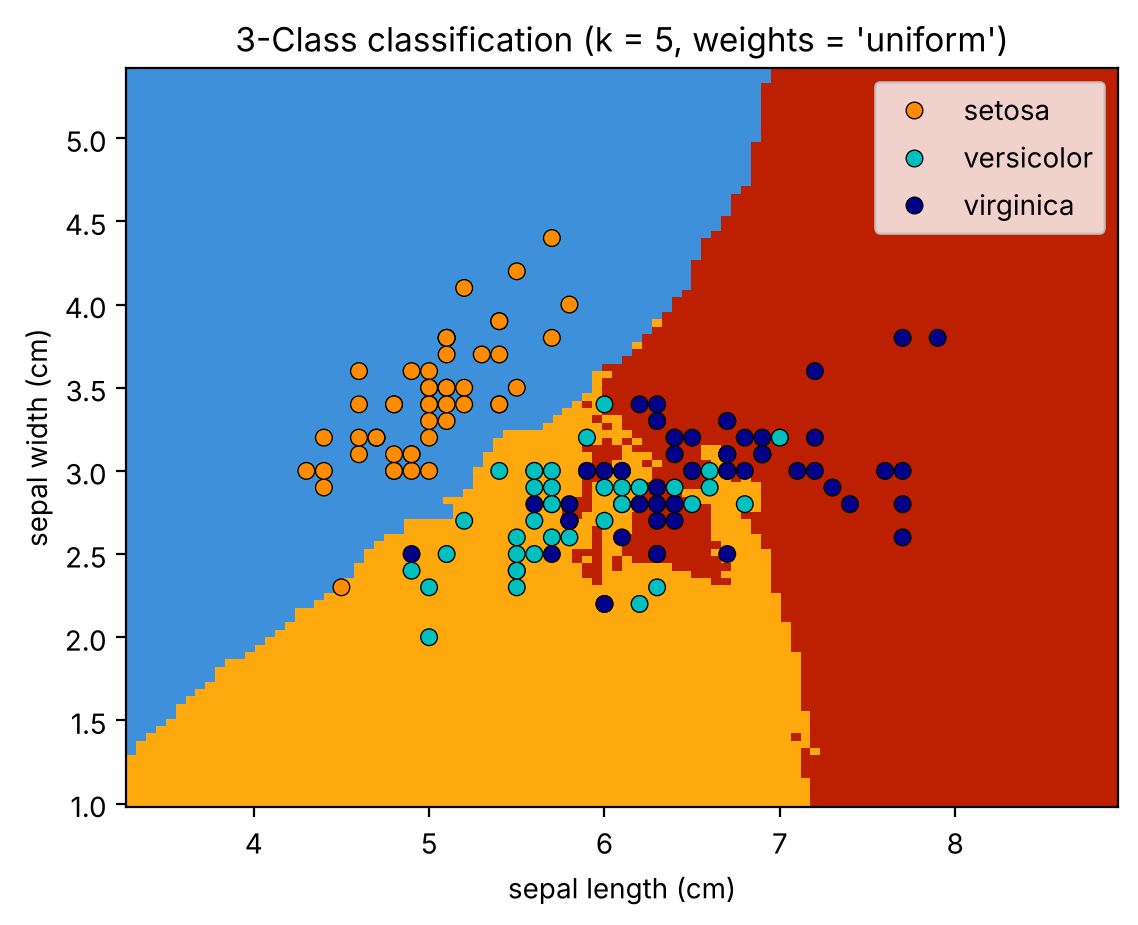

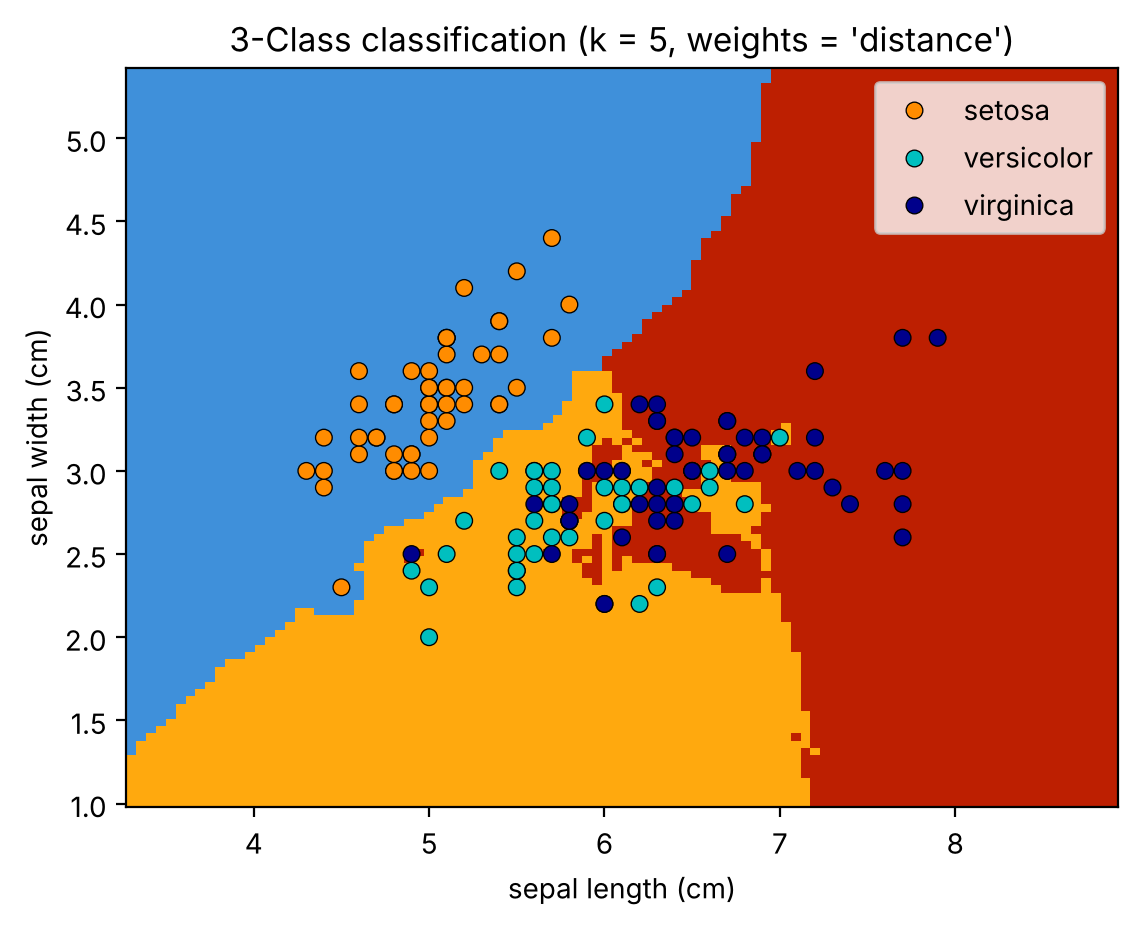

In [13]:
# Visualization for knn with k=5
n_neighbors=5
# we'll use only two features to simplify things
X = iris.data[:, :2]
y = iris.target
# Create color maps
cmap_light = ListedColormap(["orange", "cyan", "cornflowerblue"])
cmap_bold = ["darkorange", "c", "darkblue"]

for weights in ["uniform", "distance"]:
    # we create an instance of Neighbours Classifier and fit the data.
    clf = neighbors.KNeighborsClassifier(n_neighbors, weights=weights)
    clf.fit(X, y)

    _, ax = plt.subplots()
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        cmap=cmap_light,
        ax=ax,
        response_method="predict",
        plot_method="pcolormesh",
        xlabel=iris.feature_names[0],
        ylabel=iris.feature_names[1],
        shading="auto",
    )

    # Plot also the training points
    sns.scatterplot(
        x=X[:, 0],
        y=X[:, 1],
        hue=iris.target_names[y],
        palette=cmap_bold,
        alpha=1.0,
        edgecolor="black",
    )
    plt.title(
        "3-Class classification (k = %i, weights = '%s')" % (n_neighbors, weights)
    )

plt.show()